# M00-3 | Decomposition：為什麼 PT2E 在「還沒拆散」的圖上標註

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m00_export_basics/03_decomposition.ipynb)

ATen op 可以再拆成更底層、更小的 op，這叫 **decomposition**。`torch.export` 預設給的圖還沒拆：
`conv2d` 是一個 `aten.conv2d.default`，`batch_norm` 是一個 `aten.batch_norm.default`。
呼叫 `ep.run_decompositions(表)` 之後，大 op 會依傳入的 decomposition 表拆開。拆多深取決於表：

| 呼叫 | 以 conv + bn 為例 |
|---|---|
| `ep.run_decompositions({})`（空表，本 notebook 用這個） | `batch_norm` → `_native_batch_norm_legit_no_training` + `getitem`；`conv2d` 不變 |
| `ep.run_decompositions()`（預設表，Core ATen） | `conv2d` 也變成 `convolution` |

這對量化的意義：quantizer 要找的是 conv-bn-relu 這種「語意層級」的樣式，拆散之後就難認了。
所以 PT2E 在 decompose **之前**標註；convert 完、交給後端時，再由後端決定要拆到多深。

- **A.** 同一個 ExportedProgram，拆之前與拆之後的圖。
- **B.** 整張圖的 op 增減，以及「要比對幾個 node」。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m00_export_basics")

In [1]:
import torch
from torch.export import export

from common.graph_utils import diff_ops, short
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. decompose 前後的 stem

模型是 `TinyConvNet`（stem、block、head_conv 裡共 4 組 conv-bn-relu），先 `.eval()`。

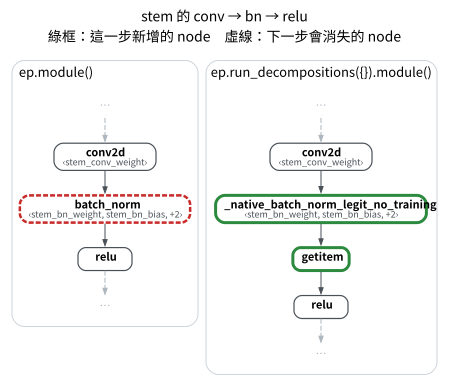

In [2]:
ep = export(get_model("tiny").eval(), example_inputs())
gm_pre = ep.module()                          # PT2E 在這一層標註
gm_post = ep.run_decompositions({}).module()  # 傳入空的 decomposition 表
draw_stages([(gm_pre, "ep.module()"), (gm_post, "ep.run_decompositions({}).module()")],
            focus=["conv2d", "batch_norm", "relu"], hops=0, title="stem 的 conv → bn → relu")

`batch_norm`（虛線，下一步消失）變成兩個 node（綠框）：`_native_batch_norm_legit_no_training` 回傳好幾個 tensor，
`getitem` 從中取出主要的輸出。`conv2d`、`relu` 維持原樣。

注意 `run_decompositions` 不會修改 `ep`，而是回傳一個新的 ExportedProgram，所以 `gm_pre` 不受影響。

## B. 整張圖的 op 增減

In [3]:
print(f"node 數量（含 get_attr、placeholder、output）：gm_pre {len(gm_pre.graph.nodes)} → gm_post {len(gm_post.graph.nodes)}")
table(diff_ops(gm_pre, gm_post, "gm_pre", "gm_post", tablefmt="html"))

node 數量（含 get_attr、placeholder、output）：gm_pre 47 → gm_post 51


op,gm_pre,gm_post,delta
_native_batch_norm_legit_no_training,0,4,4
batch_norm,4,0,-4
flatten,1,0,-1
getitem,0,4,4
view,0,1,1
adaptive_avg_pool2d,1,1,0
add,1,1,0
conv2d,4,4,0
linear,1,1,0
max_pool2d,2,2,0


In [4]:
def count(gm, op):
    return sum(1 for n in gm.graph.nodes if n.op == "call_function" and short(n.target) == op)


assert count(gm_pre, "batch_norm") == 4 and count(gm_post, "batch_norm") == 0
assert count(gm_post, "_native_batch_norm_legit_no_training") == 4 and count(gm_post, "getitem") == 4
assert count(gm_post, "conv2d") == count(gm_pre, "conv2d")
assert count(gm_pre, "flatten") == 1 and count(gm_post, "view") == 1

- 4 個 `batch_norm` 都變成 `_native_batch_norm_legit_no_training` + `getitem`。
- forward 裡的 `.flatten(1)` 也被換成 `view`。
- `conv2d`、`relu`、`max_pool2d`、`linear` 維持原樣（空表只做最基本的轉換；用預設表才會把 conv2d 拆成 convolution）。

**思考題**：如果要在 `gm_post` 上找 conv + bn + relu 這個樣式，要比對幾個 node？

In [5]:
def chain_after(gm, start):
    """從 start 一路沿著「唯一的使用者」往下走，回傳經過的 op 名稱。"""
    node, ops = next(n for n in gm.graph.nodes if n.name == start), []
    while node.op == "call_function":
        ops.append(short(node.target))
        if short(node.target) == "relu" or len(node.users) != 1:
            break
        node = next(iter(node.users))
    return ops


pre_chain, post_chain = chain_after(gm_pre, "conv2d"), chain_after(gm_post, "conv2d")
print("gm_pre ：", " → ".join(pre_chain))
print("gm_post：", " → ".join(post_chain))
assert len(pre_chain) == 3 and len(post_chain) == 4

gm_pre ： conv2d → batch_norm → relu
gm_post： conv2d → _native_batch_norm_legit_no_training → getitem → relu


拆之前比對 3 個 node，拆之後要 4 個，而且中間多了一個只是「取值」的 `getitem`。
若後端用更深的 decomposition，batch norm 還會拆成更多算術 node，樣式更難認。
所以標註要趁 conv + bn + relu 的語意還清楚時做：PT2E 的 quantizer 拿到的就是 `ep.module()` 這一層的圖。

## 小結

- `run_decompositions(表)` 把大 op 拆成小 op，拆多深由表決定；它回傳新的 ExportedProgram。
- PT2E 在拆之前標註，因為語意層級的樣式（conv-bn-relu）在這一層最好認。
- 拆到多深是後端的事：例如 Core ATen 那組約 180 個 op，是給「想把要實作的 op 數量降到最少」的後端用的。